Dataset 1

Original Dataset:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


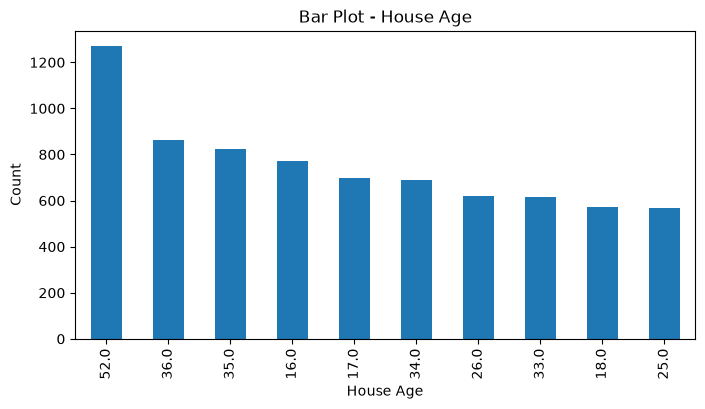

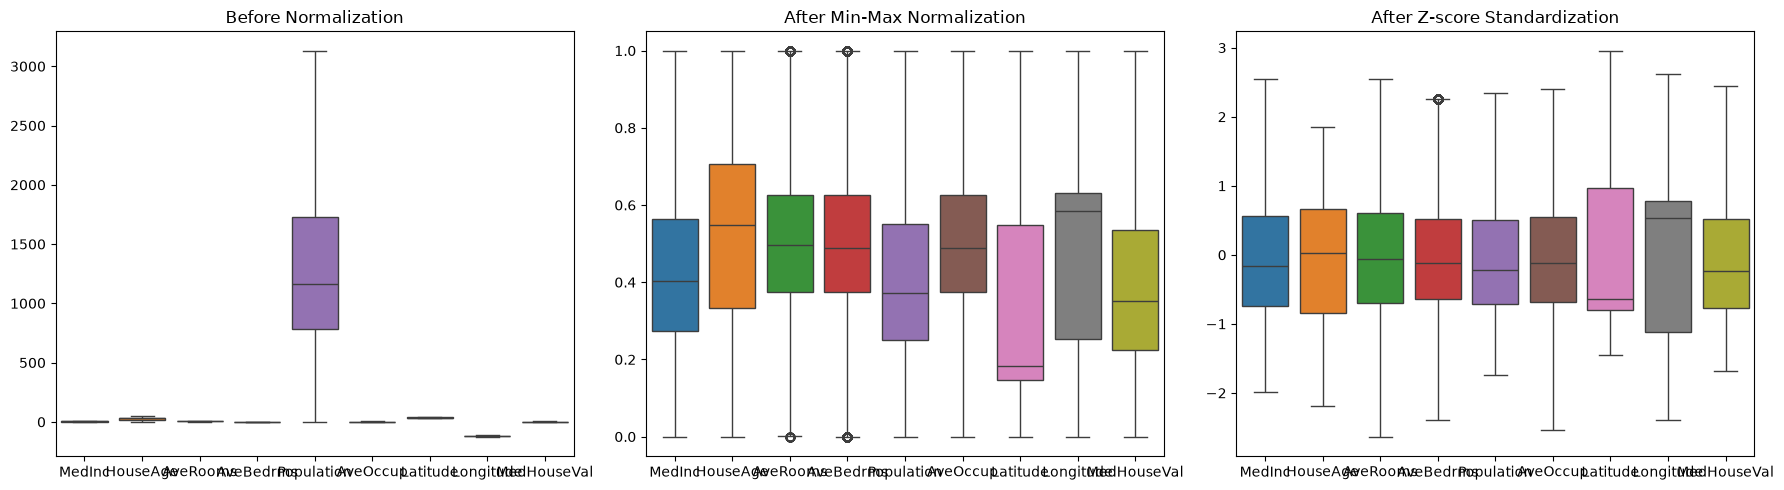

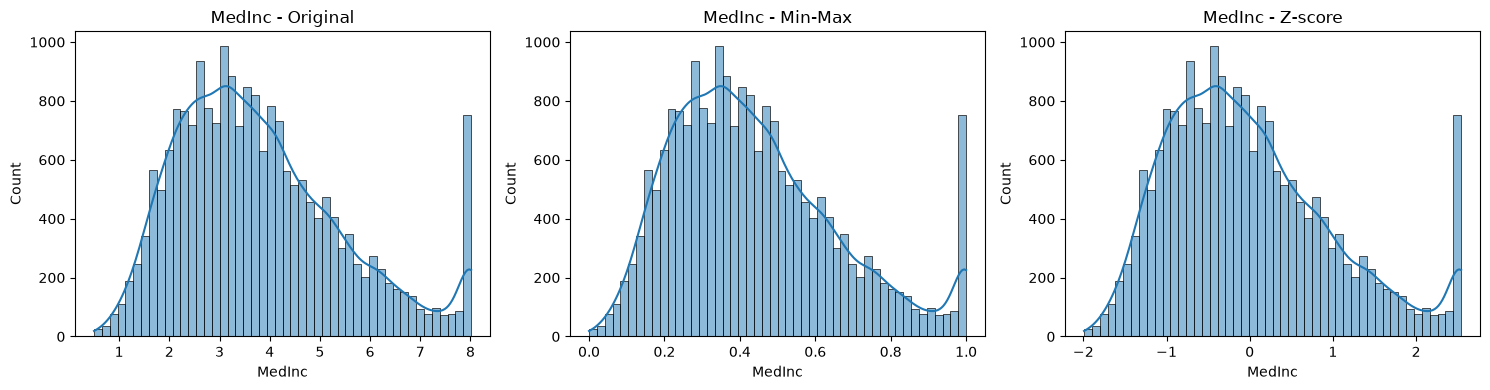

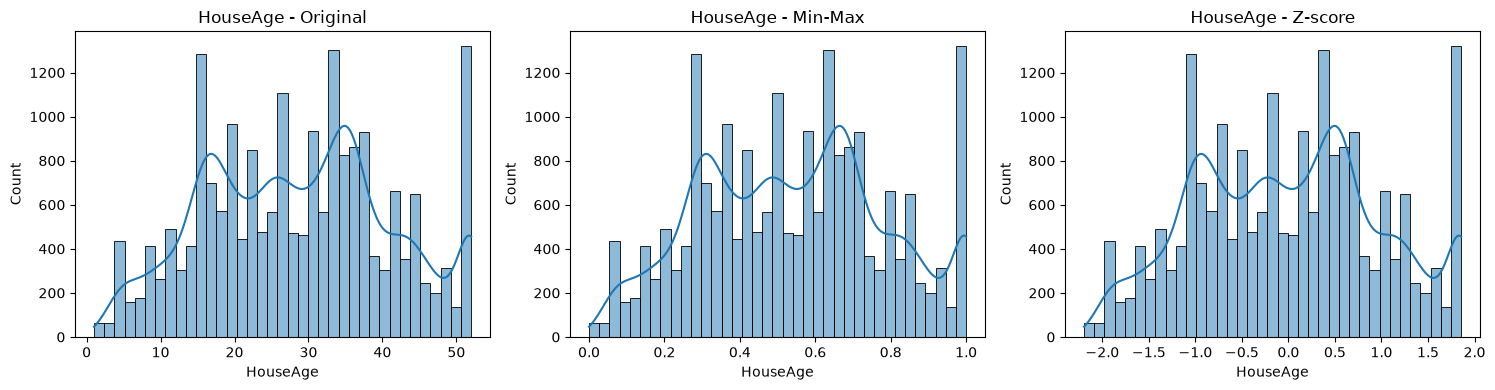

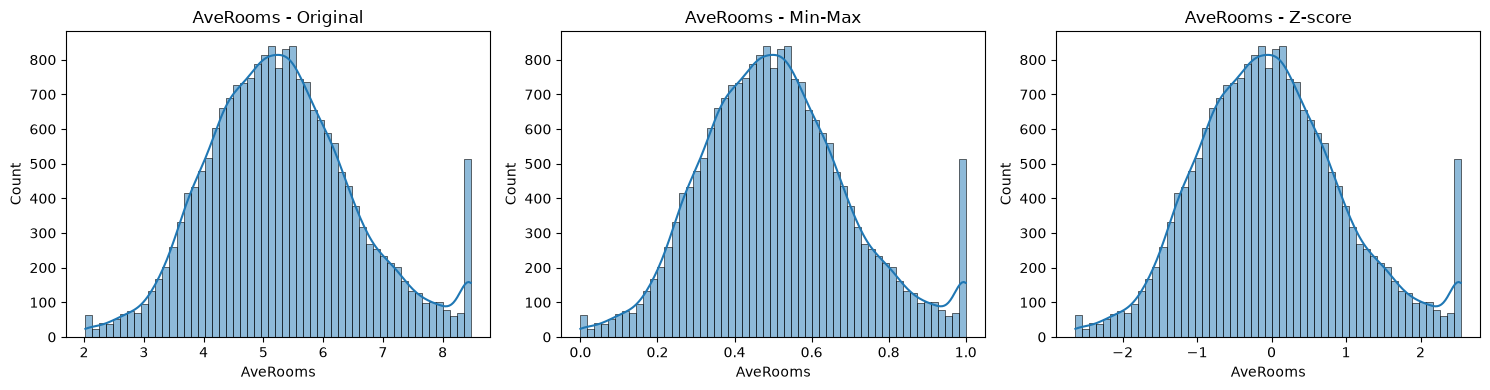

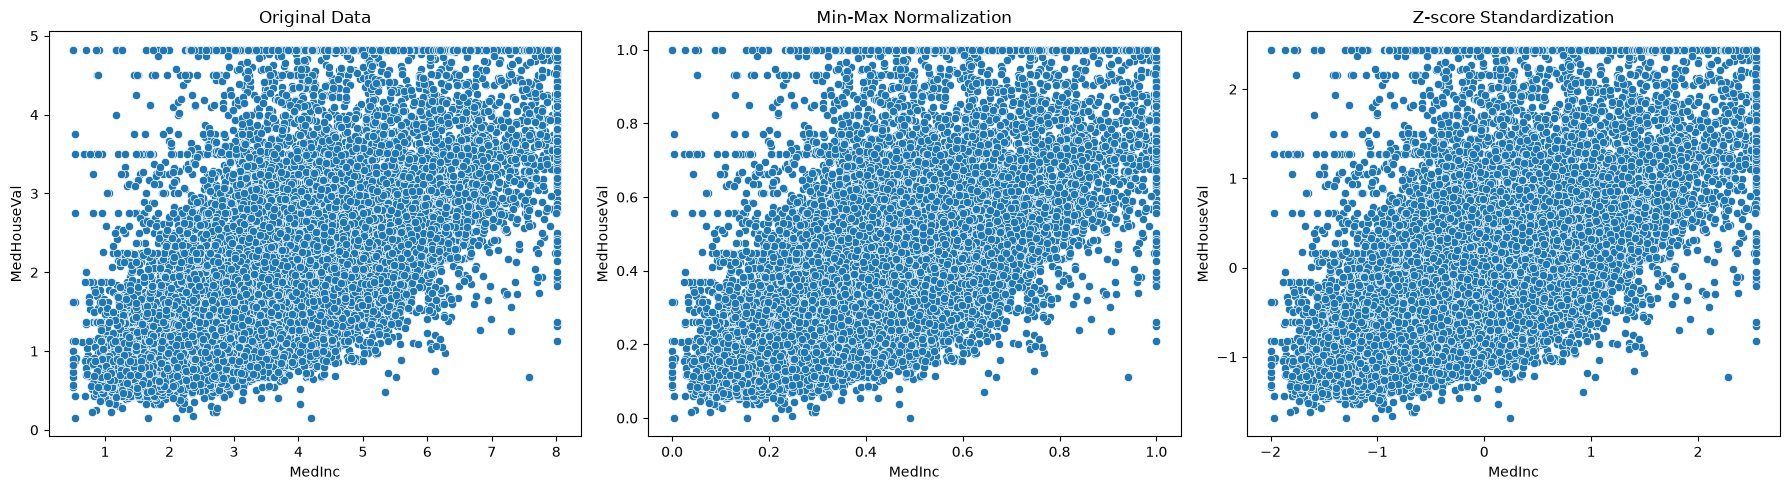


Min-Max Normalized Data:
     MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  1.000000  0.784314  0.769532   0.422435    0.101950  0.411895  0.567481   
1  1.000000  0.392157  0.653814   0.283508    0.766379  0.281190  0.565356   
2  0.899426  1.000000  0.971808   0.555229    0.157558  0.484240  0.564293   
3  0.684562  1.000000  0.588542   0.554193    0.177373  0.409663  0.564293   
4  0.445394  1.000000  0.660596   0.575654    0.179610  0.302194  0.564293   

   Longitude  MedHouseVal  
0   0.211155     0.936218  
1   0.212151     0.734897  
2   0.210159     0.721205  
3   0.209163     0.698099  
4   0.209163     0.700025  

Z-score Standardized Data:
     MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  2.541006  0.982143  1.347665  -0.424488   -1.325821 -0.497871  1.052548   
1  2.541006 -0.607019  0.749027  -1.070004    1.389936 -1.142781  1.043185   
2  2.085156  1.856182  2.394098   0.192534   -1.098528 -0.140910  1.038503 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import MinMaxScaler, StandardScaler

data = fetch_california_housing(as_frame=True)
df = data.frame

print("Original Dataset:")
print(df.head())

df = df.fillna(df.median(numeric_only=True))

df = df.drop_duplicates()

for col in df.select_dtypes(include=np.number).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

cols = df.select_dtypes(include=np.number).columns

minmax = MinMaxScaler()
df_minmax = df.copy()
df_minmax[cols] = minmax.fit_transform(df[cols])

standard = StandardScaler()
df_standard = df.copy()
df_standard[cols] = standard.fit_transform(df[cols])

plt.figure(figsize=(8, 4))
df["HouseAge"].value_counts().head(10).plot(kind="bar")
plt.title("Bar Plot - House Age")
plt.xlabel("House Age")
plt.ylabel("Count")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df[cols], ax=axes[0])
axes[0].set_title("Before Normalization")

sns.boxplot(data=df_minmax[cols], ax=axes[1])
axes[1].set_title("After Min-Max Normalization")

sns.boxplot(data=df_standard[cols], ax=axes[2])
axes[2].set_title("After Z-score Standardization")

plt.tight_layout()
plt.show()

features = ["MedInc", "HouseAge", "AveRooms"]

for col in features:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title(f"{col} - Original")

    sns.histplot(df_minmax[col], kde=True, ax=axes[1])
    axes[1].set_title(f"{col} - Min-Max")

    sns.histplot(df_standard[col], kde=True, ax=axes[2])
    axes[2].set_title(f"{col} - Z-score")

    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    x=df["MedInc"], y=df["MedHouseVal"], ax=axes[0]
)
axes[0].set_title("Original Data")

sns.scatterplot(
    x=df_minmax["MedInc"], y=df_minmax["MedHouseVal"], ax=axes[1]
)
axes[1].set_title("Min-Max Normalization")

sns.scatterplot(
    x=df_standard["MedInc"], y=df_standard["MedHouseVal"], ax=axes[2]
)
axes[2].set_title("Z-score Standardization")

plt.tight_layout()
plt.show()

print("\nMin-Max Normalized Data:")
print(df_minmax.head())

print("\nZ-score Standardized Data:")
print(df_standard.head())

print("\nPreprocessing Completed Successfully!")

Dataset 2

Original Dataset:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0  

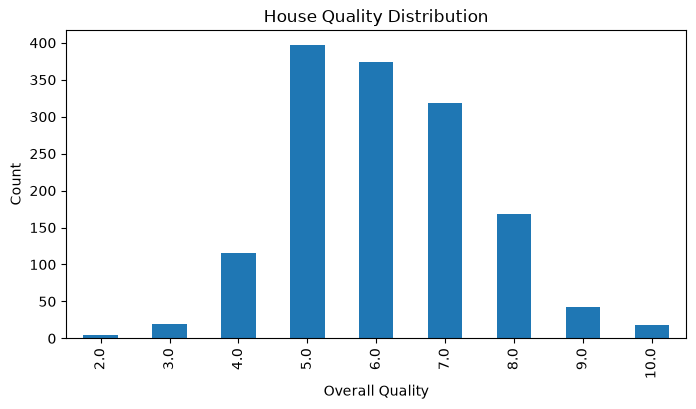

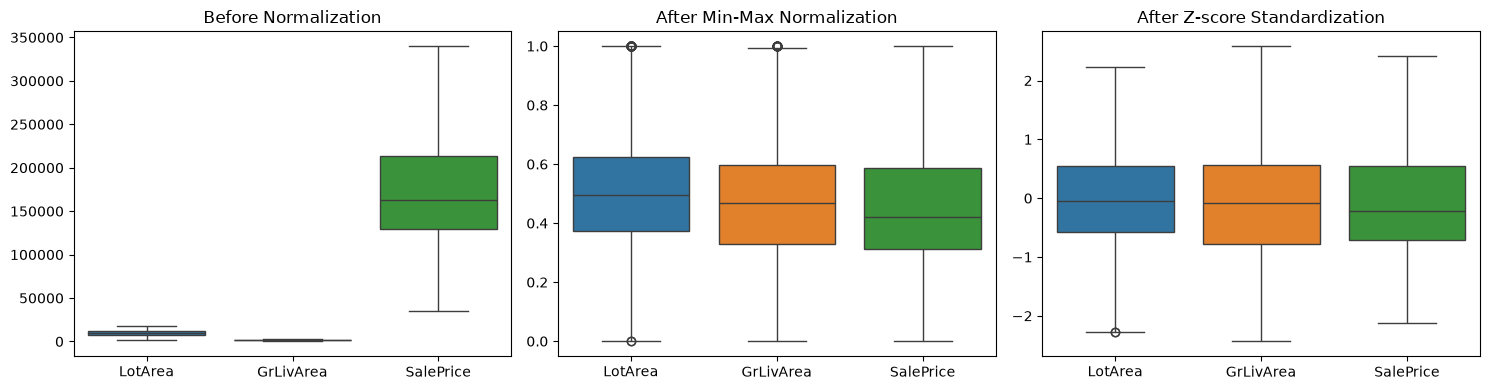

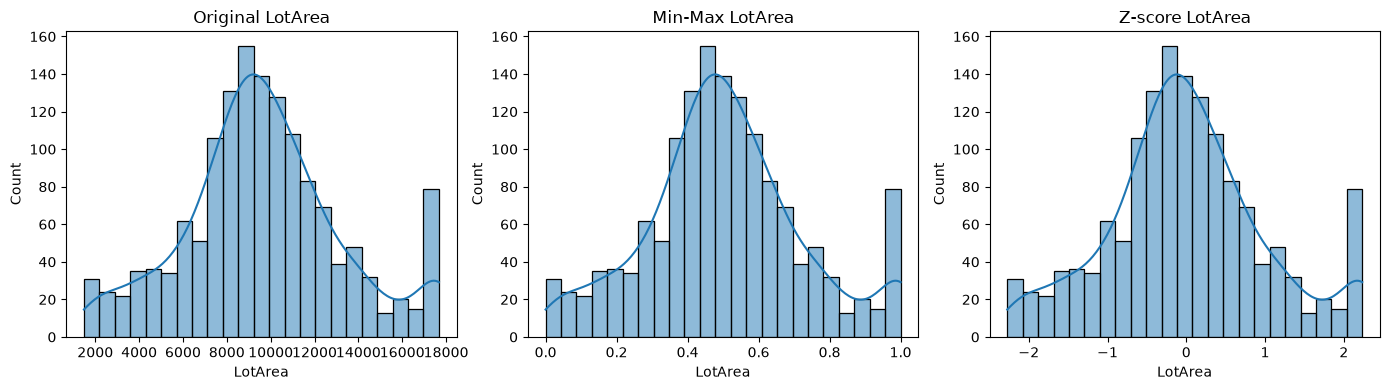

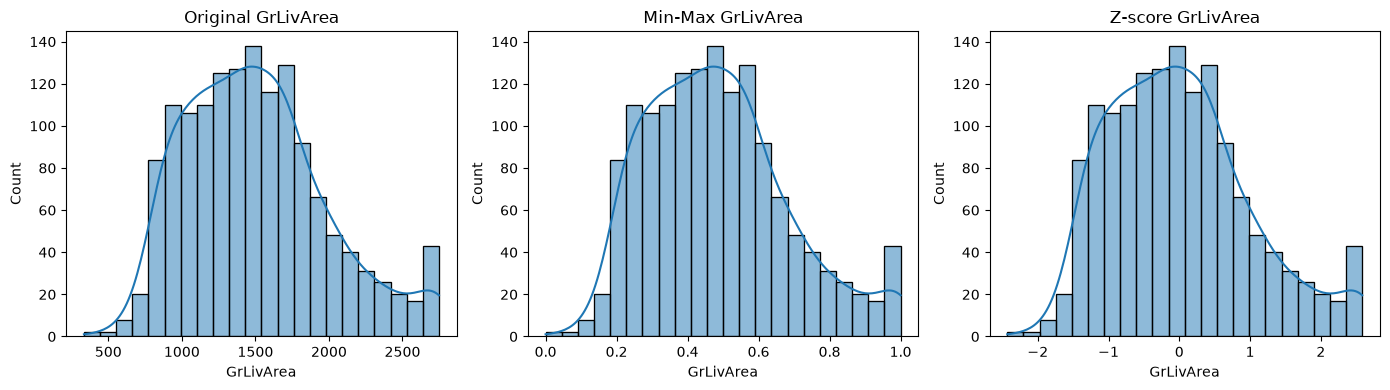

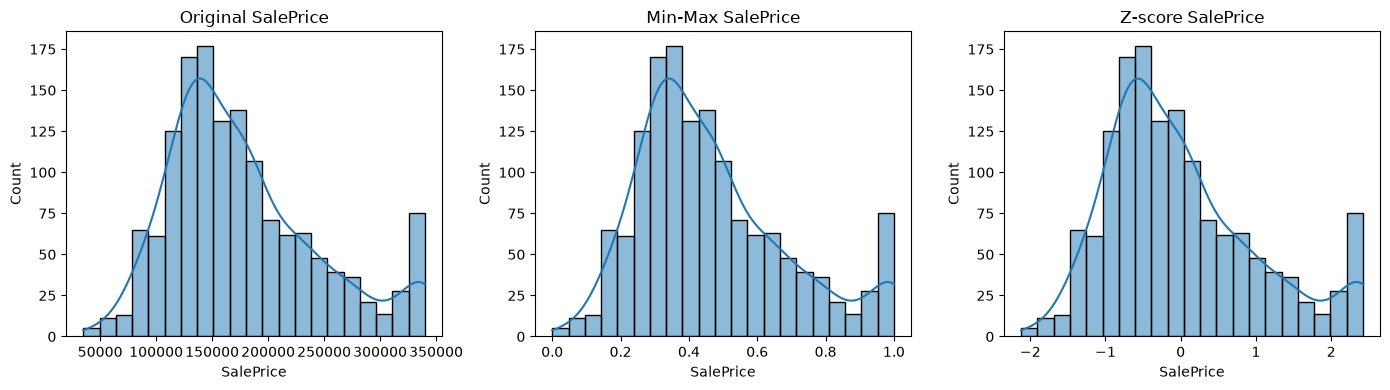

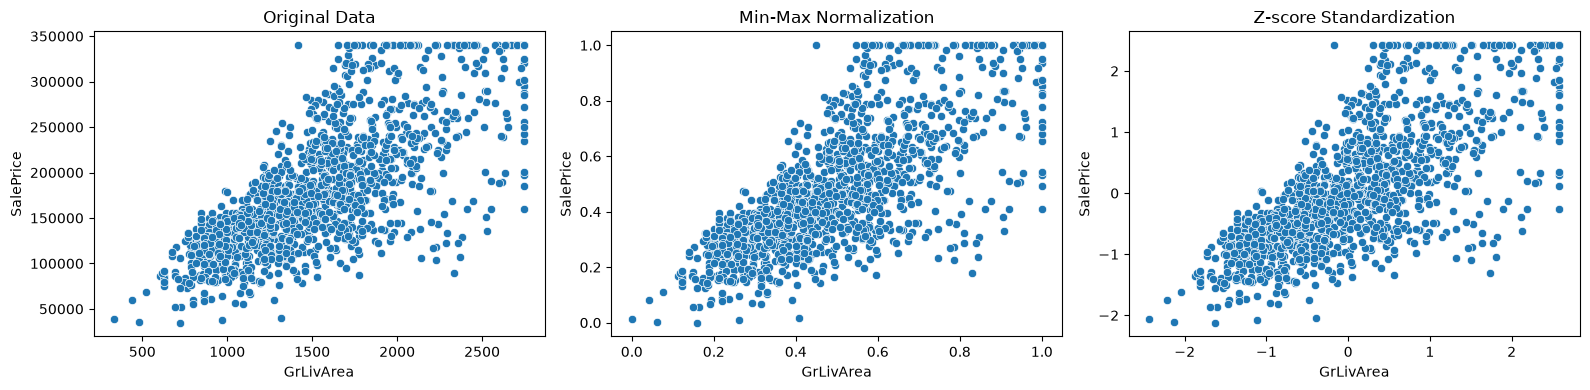


Preprocessed Dataset:
    Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0  1.0        60.0       RL         65.0   8450.0   Pave  Grvl      Reg   
1  2.0        20.0       RL         80.0   9600.0   Pave  Grvl      Reg   
2  3.0        60.0       RL         68.0  11250.0   Pave  Grvl      IR1   
3  4.0        70.0       RL         60.0   9550.0   Pave  Grvl      IR1   
4  5.0        60.0       RL         84.0  14260.0   Pave  Grvl      IR1   

  LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
1         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
2         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
3         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
4         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   

  MoSold  YrSold  SaleType  SaleCondition  SalePrice  
0    2.0  2008.0    

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df = fetch_openml(data_id=42165, as_frame=True).frame

print("Original Dataset:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum().sum())

num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

df[num_cols] = SimpleImputer(strategy="median").fit_transform(df[num_cols])

df[cat_cols] = SimpleImputer(
    strategy="most_frequent"
).fit_transform(df[cat_cols])

df = df.drop_duplicates()

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

minmax = MinMaxScaler()
df_minmax = df.copy()

df_minmax[num_cols] = minmax.fit_transform(df[num_cols])

standard = StandardScaler()
df_standard = df.copy()

df_standard[num_cols] = standard.fit_transform(df[num_cols])

plt.figure(figsize=(8, 4))
df["OverallQual"].value_counts().sort_index().plot(kind="bar")

plt.title("House Quality Distribution")
plt.xlabel("Overall Quality")
plt.ylabel("Count")
plt.show()

cols = ["LotArea", "GrLivArea", "SalePrice"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df[cols], ax=axes[0])
axes[0].set_title("Before Normalization")

sns.boxplot(data=df_minmax[cols], ax=axes[1])
axes[1].set_title("After Min-Max Normalization")

sns.boxplot(data=df_standard[cols], ax=axes[2])
axes[2].set_title("After Z-score Standardization")

plt.tight_layout()
plt.show()

for col in cols:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title("Original " + col)

    sns.histplot(df_minmax[col], kde=True, ax=axes[1])
    axes[1].set_title("Min-Max " + col)

    sns.histplot(df_standard[col], kde=True, ax=axes[2])
    axes[2].set_title("Z-score " + col)

    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.scatterplot(
    x=df["GrLivArea"], y=df["SalePrice"], ax=axes[0]
)
axes[0].set_title("Original Data")

sns.scatterplot(
    x=df_minmax["GrLivArea"], y=df_minmax["SalePrice"], ax=axes[1]
)
axes[1].set_title("Min-Max Normalization")

sns.scatterplot(
    x=df_standard["GrLivArea"], y=df_standard["SalePrice"], ax=axes[2]
)
axes[2].set_title("Z-score Standardization")

plt.tight_layout()
plt.show()

print("\nPreprocessed Dataset:")
print(df.head())

print("\nMin-Max Normalized Dataset:")
print(df_minmax.head())

print("\nZ-score Standardized Dataset:")
print(df_standard.head())

print("\nRemaining Missing Values:", df.isnull().sum().sum())
print("Remaining Duplicates:", df.duplicated().sum())

print("\nPreprocessing Completed Successfully!")